[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sei-international/trase-notebooks/blob/main/public-data/indonesia-wood-pulp-examples.ipynb)

# Indonesian wood pulp: worked examples

These examples query Trase's data on Indonesian wood pulp, following the Trase insight [Indonesian pulp exports and deforestation](https://trase.earth/insights/indonesian-pulp-exports-and-deforestation-2025): where the pulp goes, who exports it, and the deforestation and emissions linked to it. Run them with *Runtime → Run all*, then change them, or ask **✦ Gemini**, at the bottom of the window, to change them for you.

New to this? Start with [Explore Trase data](https://colab.research.google.com/github/sei-international/trase-notebooks/blob/main/public-data/explore-trase-data.ipynb).

> **Demo.** This is a trial of a new way of publishing Trase data. Some descriptions are incomplete, and the data may change. For the official Trase data, go to [trase.earth](https://trase.earth).

## Connect

In [1]:
%pip install --quiet "duckdb>=1.5" geopandas folium mapclassify

import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect()
con.execute(
    "ATTACH 'ducklake:https://public.deforestationfree.com/trase.ducklake' AS trase (READ_ONLY)"
)
con.execute("USE trase.indonesia_wood_pulp_v3_2_0")

# Colours that colour-blind readers can tell apart
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#2a78d6", "#eb6834"])
plt.rcParams["axes.spines.top"] = plt.rcParams["axes.spines.right"] = False

Note: you may need to restart the kernel to use updated packages.


## Where does the pulp go?

Pulp volume each year, used in Indonesia or exported:

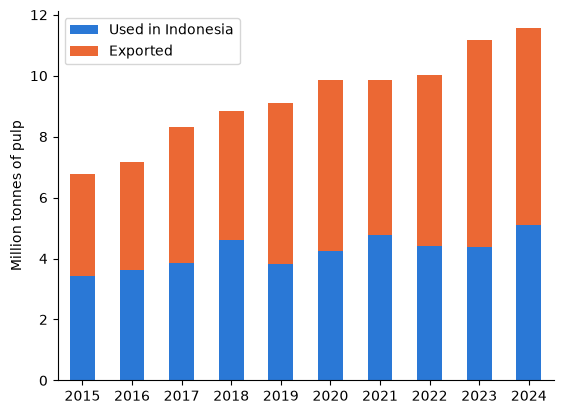

In [2]:
volume = con.sql("""
    SELECT
        year,
        sum(volume) FILTER (country_of_destination = 'INDONESIA') / 1e6 AS "Used in Indonesia",
        sum(volume) FILTER (country_of_destination <> 'INDONESIA') / 1e6 AS "Exported"
    FROM supply_chains
    GROUP BY year
    ORDER BY year
""").df()
volume.plot.bar(x="year", stacked=True, xlabel="", ylabel="Million tonnes of pulp", rot=0);

The countries it was exported to in 2024:

In [3]:
con.sql("""
    SELECT
        country_of_destination AS country,
        round(sum(volume) / 1e3) AS thousand_tonnes,
        round(100 * sum(volume) / sum(sum(volume)) OVER ()) AS percent_of_exports
    FROM supply_chains
    WHERE year = 2024 AND country_of_destination <> 'INDONESIA'
    GROUP BY country
    ORDER BY thousand_tonnes DESC
    LIMIT 10
""").df()

,country,thousand_tonnes,percent_of_exports
0,CHINA (MAINLAND),4984.0,77.0
1,INDIA,383.0,6.0
2,SOUTH KOREA,273.0,4.0
3,BANGLADESH,217.0,3.0
4,VIETNAM,112.0,2.0
5,SAUDI ARABIA,108.0,2.0
6,NEW ZEALAND,93.0,1.0
7,SINGAPORE,71.0,1.0
8,MALAYSIA,59.0,1.0
9,CHINA (HONG KONG),36.0,1.0


## Who produces it?

The share of each pulp mill's company group in 2024. Two groups, Royal Golden Eagle and Sinar Mas, handle almost all of it.

In [4]:
con.sql("""
    SELECT
        pulp_mill_corporate_group AS company_group,
        round(sum(volume) / 1e6, 2) AS million_tonnes,
        round(100 * sum(volume) / sum(sum(volume)) OVER ()) AS percent
    FROM supply_chains
    WHERE year = 2024
    GROUP BY company_group
    ORDER BY million_tonnes DESC
""").df()

,company_group,million_tonnes,percent
0,SINAR MAS,6.65,58.0
1,ROYAL GOLDEN EAGLE,4.42,38.0
2,MARUBENI,0.49,4.0


## How much forest is cleared for pulpwood?

Natural forest cleared for pulpwood plantations each year, across Indonesia. It fell by more than half in 2024, after rising since 2017.

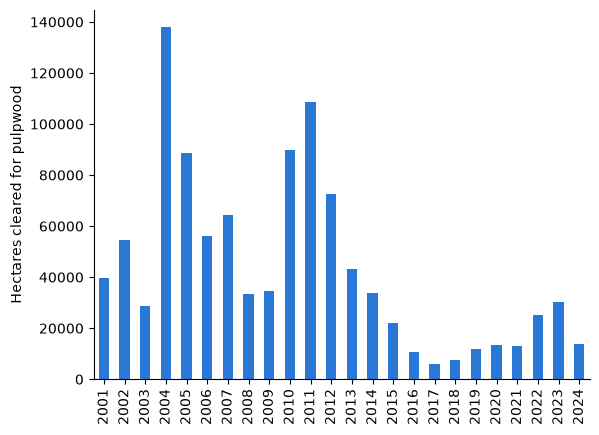

In [5]:
deforestation = con.sql("""
    SELECT year, annual_deforestation_ha AS hectares
    FROM spatial_metrics
    WHERE level = 'country' AND annual_deforestation_ha IS NOT NULL
    ORDER BY year
""").df()
deforestation.plot.bar(x="year", legend=False, xlabel="", ylabel="Hectares cleared for pulpwood");

## Did the mills' suppliers clear it?

Forest cleared for pulpwood inside concessions, split by whether the concession supplied a pulp mill that year. Since 2015, about four fifths was cleared in concessions that supplied none.

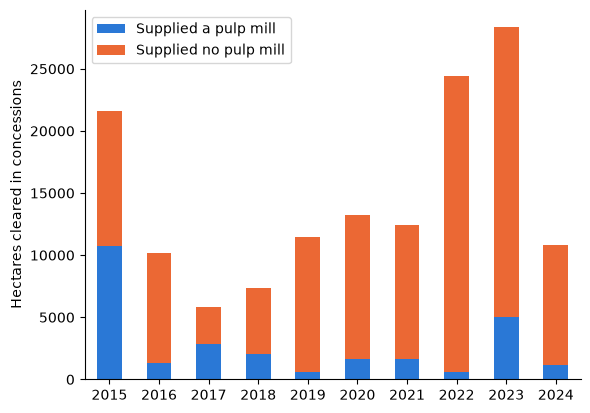

In [6]:
suppliers = con.sql("""
    WITH in_concessions AS (
        SELECT year, sum(annual_deforestation_ha) AS hectares
        FROM spatial_metrics
        WHERE level = 'wood-pulp-concession'
        GROUP BY year
    ),
    in_suppliers AS (
        SELECT year, sum(annual_woodpulp_deforestation) AS hectares
        FROM supply_chains
        GROUP BY year
    )
    SELECT
        year,
        in_suppliers.hectares AS "Supplied a pulp mill",
        in_concessions.hectares - in_suppliers.hectares AS "Supplied no pulp mill"
    FROM in_concessions
    JOIN in_suppliers USING (year)
    ORDER BY year
""").df()
suppliers.plot.bar(x="year", stacked=True, xlabel="", ylabel="Hectares cleared in concessions", rot=0);

## Which mills buy from the concessions with the most deforestation?

Each mill's share of the deforestation inside the concessions that supplied it, against its share of the volume, in 2023 and 2024. Balikpapan Chip Lestari handles about 2% of the volume, but its suppliers account for almost half of the deforestation.

In [7]:
con.sql("""
    SELECT
        pulp_mill,
        pulp_mill_corporate_group AS company_group,
        round(100 * sum(volume) / sum(sum(volume)) OVER ()) AS percent_of_volume,
        round(100 * sum(concession_deforestation) / sum(sum(concession_deforestation)) OVER ())
            AS percent_of_deforestation
    FROM supply_chains
    WHERE year IN (2023, 2024)
    GROUP BY ALL
    ORDER BY percent_of_deforestation DESC
""").df()

,pulp_mill,company_group,percent_of_volume,percent_of_deforestation
0,BALIKPAPAN CHIP LESTARI,ROYAL GOLDEN EAGLE,2.0,46.0
1,APRIL,ROYAL GOLDEN EAGLE,34.0,25.0
2,INDAH KIAT,SINAR MAS,26.0,18.0
3,OKI,SINAR MAS,22.0,4.0
4,LONTAR PAPYRUS,SINAR MAS,9.0,4.0
5,TOBA PULP LESTARI,ROYAL GOLDEN EAGLE,1.0,3.0
6,TANJUNG ENIM LESTARI,MARUBENI,4.0,0.0


## Map: where was forest cleared?

Forest cleared for pulpwood in each concession from 2015 to 2024. Zoom in, and hover over a concession for its name, its deforestation, and whether it supplied a mill in 2024. The boundaries take a few seconds to load.

In [ ]:
import geopandas as gpd

con.execute("INSTALL spatial; LOAD spatial;")
concessions = con.sql("""
    WITH deforestation AS (
        SELECT trase_id, sum(annual_deforestation_ha) AS hectares
        FROM spatial_metrics
        WHERE level = 'wood-pulp-concession'
        GROUP BY trase_id
    ),
    suppliers_2024 AS (
        SELECT DISTINCT wood_supplier_trase_id AS trase_id, true AS supplied
        FROM supply_chains
        WHERE year = 2024
    )
    SELECT
        name,
        round(hectares) AS deforestation_2015_2024_ha,
        coalesce(supplied, false) AS supplied_a_mill_in_2024,
        ST_AsHEXWKB(ST_SimplifyPreserveTopology(geometry, 0.002)) AS boundary
    FROM regions
    JOIN deforestation USING (trase_id)
    LEFT JOIN suppliers_2024 USING (trase_id)
    WHERE node_type_slug = 'wood-pulp-concession' AND geometry IS NOT NULL
    -- a concession whose boundary changed has a row per version: keep the latest
    QUALIFY row_number() OVER (PARTITION BY trase_id ORDER BY year_end DESC NULLS FIRST) = 1
""").df()
concessions = gpd.GeoDataFrame(
    concessions.drop(columns="boundary"),
    geometry=gpd.GeoSeries.from_wkb(concessions["boundary"]),
    crs="EPSG:4326",
)
concessions.explore(
    column="deforestation_2015_2024_ha",
    cmap="Oranges",
    scheme="NaturalBreaks",
    k=5,
    style_kwds={"color": "#555", "weight": 0.5},
    legend_kwds={"colorbar": False, "fmt": "{:,.0f}", "caption": "Hectares cleared, 2015–2024"},
)

## How much does drained peat emit?

Pulpwood planted on drained peatland emits greenhouse gases as the peat decomposes and subsides, year after year, whether or not more forest is cleared. These emissions rose every year from 2015 to 2024.

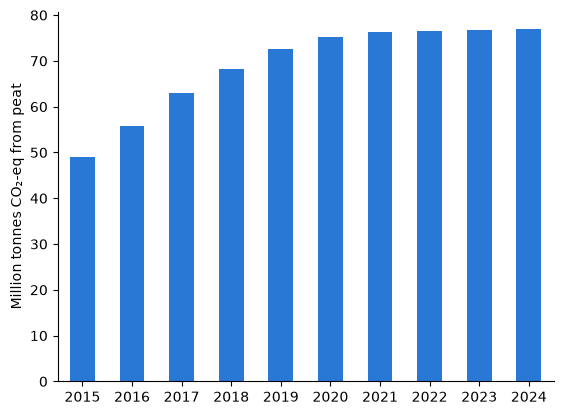

In [9]:
peat = con.sql("""
    SELECT year, sum(emission_subsidence_co2) / 1e6 AS megatonnes
    FROM spatial_metrics
    WHERE level = 'wood-pulp-concession'
    GROUP BY year
    ORDER BY year
""").df()
peat.plot.bar(x="year", legend=False, xlabel="", ylabel="Million tonnes CO₂-eq from peat", rot=0);

## Go further

Ask **✦ Gemini** to take an example further, for example:

> Using `con`, draw the map above for 2024 only, and colour the concessions that supplied a mill differently.

> Using `con`, split the chart of forest cleared for pulpwood by province.

Every column has a description: `con.sql("SELECT table_name, column_name, comment FROM duckdb_columns() WHERE database_name = 'trase'").df()` lists them. To read more:

- [Indonesian pulp exports and deforestation](https://trase.earth/insights/indonesian-pulp-exports-and-deforestation-2025), the Trase insight these examples follow.
- [Machine-friendly Trase Data](https://public.deforestationfree.com/index.html): every dataset, its files and its documentation, with the methodology.
- [trase.earth](https://trase.earth): Trase's insights, reports and tools.